### **Naive Bayes End-to-End ML Pipeline — Group Lab (3 Members)**

**Goal:** As a group of **3**, build a complete pipeline that predicts Titanic passenger survival with **Naive Bayes** — from raw data all the way to a final, evaluated model. The lab is split into **3 parts**, one per group member, but **everyone should read and understand every part** — you'll need each other's outputs to finish the pipeline.

**Dataset:** We'll use `seaborn`'s **built-in** Titanic dataset — no download or upload needed:
```python
titanic = sns.load_dataset('titanic')
```
(If your instructor asks you to use a different/self-generated dataset instead, the same structure below still applies — just swap the loading step.)

**How the 3 parts connect (the pipeline, in order):**

| Part | Member | Focus | Concepts Covered |
|---|---|---|---|
| **1** | **A** | Explore the raw data | EDA, Data Visualization, Bayes' Theorem (by hand) |
| **2** | **B** | Clean & transform the data | Missing Values, Binning, Binarization, Ordinal/One-Hot/Label Encoding, Column Transformer, Function/Power Transformer, Standardization & Normalization |
| **3** | **C** | Build & evaluate the model | Naive Bayes (from scratch + `sklearn`), Cross-Validation, Evaluation Metrics |

**Rule:** Member B's final output (`X_train_final`, `X_test_final`, `y_train`, `y_test`) is exactly what Member C needs as input. Member A's Section 1.7 (Bayes' Theorem by hand) is the conceptual foundation Member C will re-use in Section 3.1. **Talk to each other before starting your part.**

Cells marked `# TODO` are where you write your own code. Everything else (imports, structure, explanations) is provided to keep the group in sync.

#### **0. Shared Setup (Everyone Runs This First)**

Run this section before splitting into your parts — it loads the libraries and the dataset every part depends on.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
sns.set(style='whitegrid')


In [4]:
# Built-in dataset - no download required
titanic = sns.load_dataset('titanic')
titanic.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


**A quick look at what we're working with:** each row is one passenger. Key columns: `survived` (target, 0/1), `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked`, `who`, `alive` (text version of `survived`), `deck` (mostly missing).

#### **Part 1 (Member A): Exploratory Data Analysis & Bayes' Theorem Foundations**

**Your job:** understand the raw data before anyone touches it — its shape, quality issues, and the patterns that make Naive Bayes a sensible model choice here.

**1.1 Dataset Structure**

Check the shape, column data types, and general info of `titanic`.

In [5]:
# TODO: print the shape of the dataset
print("Shape:", titanic.shape)
print("\nDataset information:")
# TODO: use .info() to see column dtypes and non-null counts
titanic.info()



Shape: (891, 15)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


**1.2 Statistical Summary**

`.describe()` gives count/mean/std/min/max/quartiles for numeric columns — a first look at scale and possible skew (e.g., compare `fare`'s mean vs its median/50%).

In [6]:
# TODO: call .describe() on titanic
print(titanic.describe())



         survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200


**1.3 Missing Value Analysis**

Which columns have missing data, and how much? This will guide Member B's cleaning strategy in Part 2.

             missing_count  missing_pct
survived                 0         0.00
pclass                   0         0.00
sex                      0         0.00
age                    177        19.87
sibsp                    0         0.00
parch                    0         0.00
fare                     0         0.00
embarked                 2         0.22
class                    0         0.00
who                      0         0.00
adult_male               0         0.00
deck                   688        77.22
embark_town              2         0.22
alive                    0         0.00
alone                    0         0.00


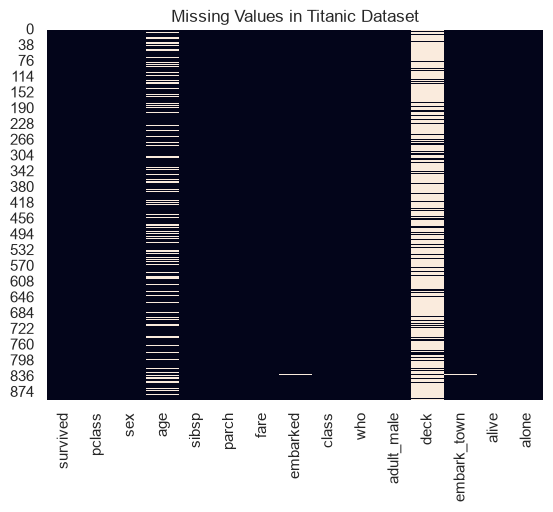

In [7]:
# TODO: compute titanic.isnull().sum()
missing_counts = titanic.isnull().sum()

# TODO: also compute it as a percentage of total rows
missing_pct = (missing_counts / len(titanic) * 100).round(2)

missing_summary = pd.DataFrame({"missing_count": missing_counts, "missing_pct": missing_pct})
print(missing_summary)

# TODO (visualization): plot a heatmap of missing values, e.g.
sns.heatmap(titanic.isnull(), cbar=False)
plt.title("Missing Values in Titanic Dataset")
plt.show()


**1.4 Target Variable Distribution**

Is `survived` balanced or imbalanced? This matters for how we should judge "accuracy" later in Part 3.

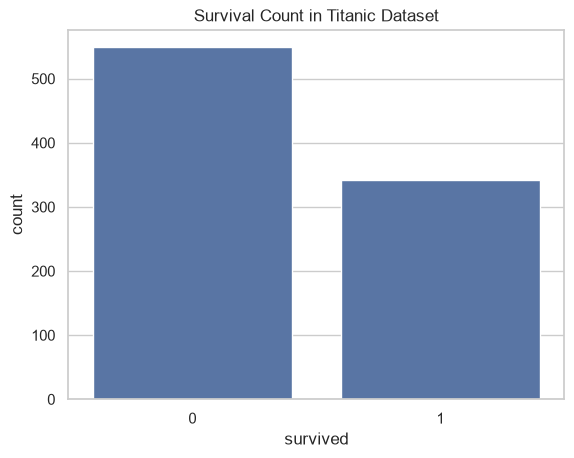

Percentage split:
survived
0    61.62
1    38.38
Name: proportion, dtype: float64


In [8]:
# TODO: sns.countplot the 'survived' column
sns.countplot(x='survived', data=titanic)
plt.title("Survival Count in Titanic Dataset")
plt.show()

# TODO: print the exact percentage split (value_counts(normalize=True))
print("Percentage split:")
print((titanic['survived'].value_counts(normalize=True) * 100).round(2))


**1.5 Univariate Analysis**

Look at `age` and `fare` individually — shape of distribution, and whether they look skewed (relevant for Member B's transformation step later).

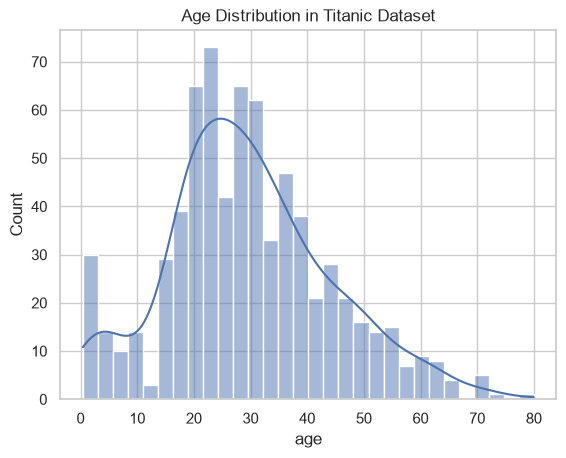

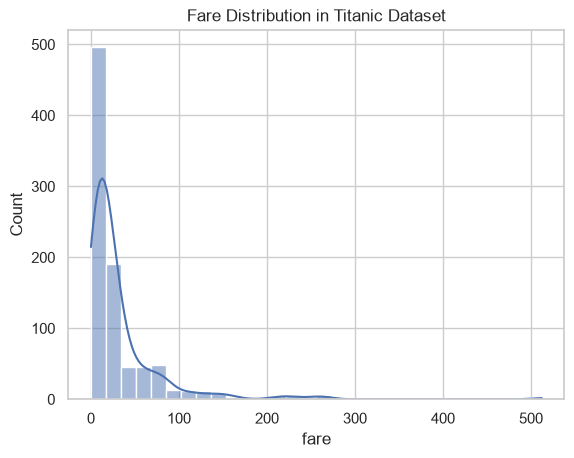

Skewness of Age: 0.38910778230082704
Skewness of Fare: 4.787316519674893


In [9]:
# TODO: plot a histogram (with KDE) of 'age'
sns.histplot(titanic['age'], kde=True, bins=30)
plt.title("Age Distribution in Titanic Dataset")
plt.show()

# TODO: plot a histogram (with KDE) of 'fare'
sns.histplot(titanic['fare'], kde=True, bins=30)
plt.title("Fare Distribution in Titanic Dataset")
plt.show()

# TODO: print titanic['age'].skew() and titanic['fare'].skew()
print("Skewness of Age:", titanic['age'].skew())
print("Skewness of Fare:", titanic['fare'].skew())





**1.6 Bivariate Analysis — Does Survival Depend on Sex and Class?**

Compute and visualize survival rate broken down by `sex`, and separately by `pclass`.

Survival rate by sex:
sex
female    0.742038
male      0.188908
Name: survived, dtype: float64
Survival rate by passenger class:
pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64


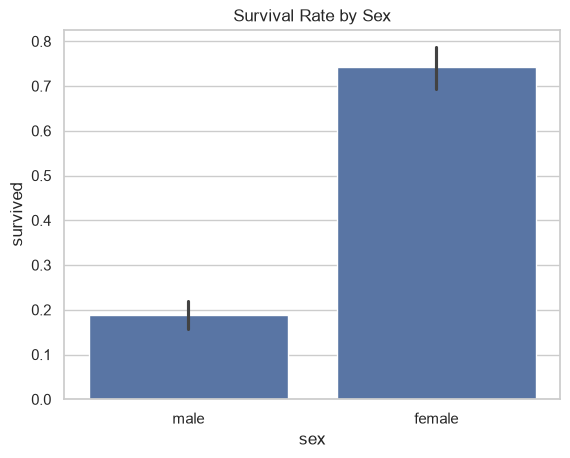

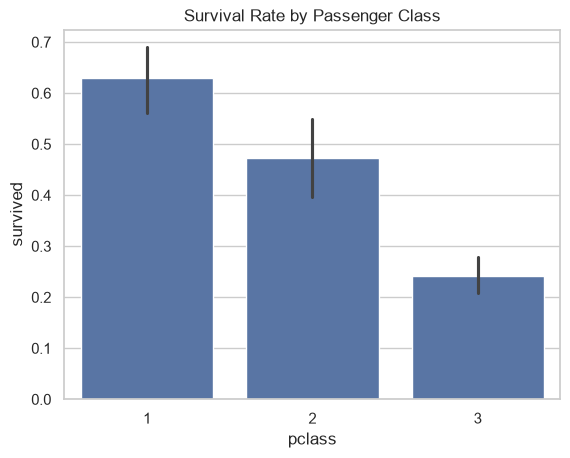

In [10]:
# TODO: titanic.groupby('sex')['survived'].mean()
print("Survival rate by sex:")
print(titanic.groupby('sex')['survived'].mean())

# TODO: titanic.groupby('pclass')['survived'].mean()
print("Survival rate by passenger class:")
print(titanic.groupby('pclass')['survived'].mean())

# TODO: visualize both with sns.barplot or sns.catplot
sns.barplot(x='sex', y='survived', data=titanic)
plt.title("Survival Rate by Sex")
plt.show()

sns.barplot(x='pclass', y='survived', data=titanic)
plt.title("Survival Rate by Passenger Class")
plt.show()



**1.7 Connecting to Bayes' Theorem**

Recall **Bayes' Theorem**:

$$P(A \mid B) = \frac{P(B \mid A)\, P(A)}{P(B)}$$

Let's estimate, **by hand**, the probability a passenger survived *given* they were female — i.e. $P(\text{Survived}=1 \mid \text{Sex}=\text{female})$ — using only priors and likelihoods computed from the data (not `groupby` directly), and then check it against the true empirical value from Section 1.6.

- $P(A) = P(\text{Survived}=1)$ → the overall survival rate
- $P(B) = P(\text{Sex}=\text{female})$ → the overall proportion of female passengers
- $P(B \mid A) = P(\text{Sex}=\text{female} \mid \text{Survived}=1)$ → among survivors, what fraction were female?

In [11]:
# TODO: P_A = P(Survived = 1)          -> titanic['survived'].mean()
P_A = titanic['survived'].mean()

# TODO: P_B = P(Sex = female)             -> (titanic['sex'] == 'female').mean()
P_B = (titanic['sex'] == 'female').mean()
# TODO: P_B_given_A = P(Sex=female | Survived=1)
#       hint: filter titanic where survived == 1, then compute the fraction that are female
P_B_given_A = titanic.loc[titanic['survived'] == 1, 'sex'].eq('female').mean()

# TODO: apply Bayes' Theorem: P_A_given_B = (P_B_given_A * P_A) / P_B
P_A_given_B = (P_B_given_A * P_A) / P_B

# TODO: print P_A_given_B and compare it to titanic.groupby('sex')['survived'].mean()['female'] from Section 1.6
# They should match (up to rounding) - if not, recheck your probabilities above!
empirical_female_survival = titanic.groupby('sex')['survived'].mean()['female']

print(f"P(Survived) = {P_A:.6f}")
print(f"P(Female) = {P_B:.6f}")
print(f"P(Female | Survived) = {P_B_given_A:.6f}")
print(f"Bayes P(Survived | Female) = {P_A_given_B:.6f}")
print(f"Empirical P(Survived | Female) = {empirical_female_survival:.6f}")


P(Survived) = 0.383838
P(Female) = 0.352413
P(Female | Survived) = 0.681287
Bayes P(Survived | Female) = 0.742038
Empirical P(Survived | Female) = 0.742038


**💡 Why this matters:** Naive Bayes classifiers work by applying exactly this formula to **every feature**, multiplying the likelihoods together under the "naive" independence assumption — Member C will build on this in Part 3.

**Hand off to Member B:** the raw `titanic` DataFrame, plus your findings on which columns are missing and which numeric columns are skewed.

#### **Part 2 (Member B): Data Cleaning, Transformation & Encoding**

**Your job:** take the raw `titanic` DataFrame and Member A's findings, and produce a fully cleaned, encoded, scaled, model-ready `X_train_final` / `X_test_final`.

**2.1 Selecting Columns and Splitting Train/Test First**

We split **before** cleaning so every fitted step (imputer, encoder, scaler) is learned only from `X_train` — this avoids **data leakage** into the test set.

In [12]:
from sklearn.model_selection import train_test_split

# Keep a focused set of columns for this lab
cols = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'survived']
df = titanic[cols].copy()

# TODO: X = df.drop(columns=['survived']), y = df['survived']
X = df.drop(columns=['survived'])
y = df['survived']

# TODO: train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
#       name the results X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (712, 7)
X_test : (179, 7)
y_train: (712,)
y_test : (179,)


**2.2 Handling Missing Values**

From Part 1.3, `age` and `embarked` have missing values. Impute `age` with the **median** (robust to skew) and `embarked` with the **mode** (most frequent category) — fit on train, apply to both.

In [13]:
from sklearn.impute import SimpleImputer

# TODO: num_imputer = SimpleImputer(strategy='median')
num_imputer = SimpleImputer(strategy='median')

# TODO: fit num_imputer on X_train[['age']], then transform both X_train and X_test 'age' column
num_imputer.fit(X_train[['age']])
X_train[['age']] = num_imputer.transform(X_train[['age']])
X_test[['age']] = num_imputer.transform(X_test[['age']])

# TODO: cat_imputer = SimpleImputer(strategy='most_frequent')
cat_imputer = SimpleImputer(strategy='most_frequent')

# TODO: fit cat_imputer on X_train[['embarked']], then transform both X_train and X_test 'embarked' column
cat_imputer.fit(X_train[['embarked']])
X_train[['embarked']] = cat_imputer.transform(X_train[['embarked']])
X_test[['embarked']] = cat_imputer.transform(X_test[['embarked']])

# TODO: confirm no missing values remain with .isnull().sum()
print("Missing values in X_train:")
print(X_train.isnull().sum())
print("Missing values in X_test:")
print(X_test.isnull().sum())

Missing values in X_train:
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64
Missing values in X_test:
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64


**2.3 Binning — Creating an `age_group` Feature (Custom Binning)**

Convert continuous `age` into meaningful, ordered groups using domain knowledge — a **custom binning** approach, with edges we choose ourselves:

`Child (0–12)` < `Teen (13–19)` < `Adult (20–59)` < `Senior (60+)`

In [14]:
age_bins = [0, 12, 19, 59, 100]
age_labels = ['Child', 'Teen', 'Adult', 'Senior']

# TODO: X_train['age_group'] = pd.cut(X_train['age'], bins=age_bins, labels=age_labels)
X_train['age_group'] = pd.cut(X_train['age'], bins=age_bins, labels=age_labels)

# TODO: do the same for X_test['age_group']
X_test['age_group'] = pd.cut(X_test['age'], bins=age_bins, labels=age_labels)

# TODO: print value_counts() of the new column to sanity-check the split
print("Value counts in X_train:")
print(X_train['age_group'].value_counts())
print("Value counts in X_test:")
print(X_test['age_group'].value_counts())


Value counts in X_train:
age_group
Adult     565
Teen       74
Child      55
Senior     18
Name: count, dtype: int64
Value counts in X_test:
age_group
Adult     136
Teen       21
Child      14
Senior      8
Name: count, dtype: int64


**2.4 Binning — `fare_level` Feature (Unsupervised, Quantile Binning)**

Now try an **unsupervised** binning method on `fare`: split it into 4 **equal-frequency (quantile)** bins using `KBinsDiscretizer`, fit only on the training data.

In [15]:
from sklearn.preprocessing import KBinsDiscretizer

# TODO: kb = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')
kb = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')

# TODO: fit kb on X_train[['fare']]
kb.fit(X_train[['fare']])

# TODO: X_train['fare_level'] = kb.transform(X_train[['fare']])
X_train['fare_level'] = kb.transform(X_train[['fare']])

# TODO: X_test['fare_level']  = kb.transform(X_test[['fare']])
X_test['fare_level']  = kb.transform(X_test[['fare']])

# TODO: print kb.bin_edges_ to see the learned edges
print("Bin edges:", kb.bin_edges_)



Bin edges: [array([  0.    ,   7.8958,  14.4542,  31.    , 512.3292])]


**2.5 Binarization**

Create a simple binary flag: `is_child` = 1 if `age` < 13, else 0 — using `Binarizer`.

In [16]:
from sklearn.preprocessing import Binarizer

# TODO: binarizer = Binarizer(threshold=12.9)   # threshold is exclusive (>), so 12.9 makes 13+ map to 1... check this makes <13 -> 0
binarizer = Binarizer(threshold=12.9)

# TODO: X_train['is_child'] = binarizer.fit_transform(X_train[['age']])
X_train['is_child'] = (binarizer.fit_transform(X_train[['age']])==0).astype(int)  

# TODO: X_test['is_child']  = binarizer.transform(X_test[['age']])
X_test['is_child']  = (binarizer.transform(X_test[['age']])==0).astype(int)

print("Value counts in X_train:")
print(X_train['is_child'].value_counts())
print("Value counts in X_test:")
print(X_test['is_child'].value_counts())


Value counts in X_train:
is_child
0    657
1     55
Name: count, dtype: int64
Value counts in X_test:
is_child
0    165
1     14
Name: count, dtype: int64


**2.6 Encoding Categorical Features**

Three different encoders for three different situations:

- **Ordinal Encoding** → `age_group` has a real order (`Child < Teen < Adult < Senior`), so use `OrdinalEncoder` with that explicit order.
- **One-Hot Encoding** → `sex` and `embarked` are nominal (no order), so use `OneHotEncoder`.
- **Label Encoding** → as a quick demo only: label-encode `titanic['alive']` (the text `yes`/`no` version of the target) separately, just to see how `LabelEncoder` works on a target-like column. (We won't use this encoded column in modeling — `survived` is already numeric.)

In [17]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder

# --- Ordinal Encoding for age_group ---
# TODO: oe = OrdinalEncoder(categories=[['Child', 'Teen', 'Adult', 'Senior']])
oe = OrdinalEncoder(categories=[['Child', 'Teen', 'Adult', 'Senior']])

# TODO: fit oe on X_train[['age_group']], transform X_train and X_test 'age_group' column
oe.fit(X_train[['age_group']])
X_train['age_group_encoded'] = oe.transform(X_train[['age_group']])
X_test['age_group_encoded'] = oe.transform(X_test[['age_group']])

# Drop the original categorical age_group because its encoded version is used downstream.
X_train = X_train.drop(columns=['age_group'])
X_test = X_test.drop(columns=['age_group'])

# --- One-Hot Encoding for sex, embarked (we'll actually apply this via ColumnTransformer in 2.7) ---
# (no code needed here yet - just review the OneHotEncoder import above)

# --- Label Encoding demo on titanic['alive'] ---
# TODO: le = LabelEncoder()
le = LabelEncoder()

# TODO: alive_encoded = le.fit_transform(titanic['alive'])
alive_encoded = le.fit_transform(titanic['alive'])

# TODO: print le.classes_ and the first 10 values of alive_encoded
print("Label classes:", le.classes_)
print("First 10 encoded values:", alive_encoded[:10])

Label classes: ['no' 'yes']
First 10 encoded values: [0 1 1 1 0 0 0 0 1 1]


**2.7 Combining Everything with `ColumnTransformer`**

Instead of manually encoding and concatenating column-by-column, bundle the remaining raw categorical columns (`sex`, `embarked`) into one `ColumnTransformer`, and pass the already-processed numeric/ordinal columns straight through.

In [18]:
from sklearn.compose import ColumnTransformer

# TODO: define a ColumnTransformer with:
#   ('ohe', OneHotEncoder(drop='first'), ['sex', 'embarked'])
# and remainder='passthrough' to keep age, age_group_encoded, fare, fare_level, is_child, pclass, sibsp, parch
ct = ColumnTransformer(
    transformers=[
        ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore'), ['sex', 'embarked'])
    ],
    remainder='passthrough'
)

# TODO: fit_transform on X_train (carefusl: only fit on train!), transform on X_test
X_train = ct.fit_transform(X_train)
X_test = ct.transform(X_test)

# TODO: print the resulting shapes of X_train and X_test after this step
print("Shape of X_train after encoding:", X_train.shape)
print("Shape of X_test after encoding:", X_test.shape)



Shape of X_train after encoding: (712, 11)
Shape of X_test after encoding: (179, 11)


**2.8 Reducing Skew — Power Transformer**

From Part 1.5, `fare` is heavily right-skewed. Apply a `PowerTransformer` (Yeo-Johnson, since `fare` can be 0) to `fare` before scaling.

In [19]:
print(type(X_train))
print(X_train.shape)

<class 'numpy.ndarray'>
(712, 11)


In [20]:
from sklearn.preprocessing import PowerTransformer
import pandas as pd

# Get feature names
feature_names = ct.get_feature_names_out()

# Convert NumPy arrays back to DataFrames
X_train = pd.DataFrame(
    X_train,
    columns=feature_names,
    index=y_train.index
)

X_test = pd.DataFrame(
    X_test,
    columns=feature_names,
    index=y_test.index
)

# Create PowerTransformer
pt = PowerTransformer(method='yeo-johnson')

# fare column name after ColumnTransformer
fare_col = 'remainder__fare'

# Skewness BEFORE transformation
fare_skew_before = X_train[fare_col].skew()

# Fit ONLY on training fare
pt.fit(X_train[[fare_col]])

# Transform train and test
X_train.loc[:, fare_col] = pt.transform(
    X_train[[fare_col]]
).ravel()

X_test.loc[:, fare_col] = pt.transform(
    X_test[[fare_col]]
).ravel()

# Skewness AFTER transformation
fare_skew_after = X_train[fare_col].skew()

print(f"Fare skewness before transformation: {fare_skew_before:.4f}")
print(f"Fare skewness after transformation:  {fare_skew_after:.4f}")

Fare skewness before transformation: 4.6462
Fare skewness after transformation:  -0.0305


**2.9 Feature Scaling — Standardization vs Normalization**

Two common scaling techniques:

- **Standardization (Z-score):** $x' = \dfrac{x - \mu}{\sigma}$ → mean 0, std 1. Use `StandardScaler`.
- **Normalization (Min-Max):** $x' = \dfrac{x - \min(x)}{\max(x) - \min(x)}$ → scales to a fixed $[0,1]$ range. Use `MinMaxScaler`.

Pick **one** to apply to the final numeric columns (e.g., `age`, `fare`) — fit on train, transform both.

In [21]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import pandas as pd

# Choose scaler
scaler = StandardScaler()

# Select numeric columns
numeric_cols = X_train.select_dtypes(
    include='number'
).columns

print("Numeric columns being scaled:")
print(numeric_cols.tolist())

# Copy the data
X_train_final = X_train.copy()
X_test_final = X_test.copy()

# Fit ONLY on training data
X_train_final[numeric_cols] = scaler.fit_transform(
    X_train[numeric_cols]
)

# Transform test using the same fitted scaler
X_test_final[numeric_cols] = scaler.transform(
    X_test[numeric_cols]
)

print("Final train shape:", X_train_final.shape)
print("Final test shape :", X_test_final.shape)


Numeric columns being scaled:
['ohe__sex_male', 'ohe__embarked_Q', 'ohe__embarked_S', 'remainder__pclass', 'remainder__age', 'remainder__sibsp', 'remainder__parch', 'remainder__fare', 'remainder__fare_level', 'remainder__is_child', 'remainder__age_group_encoded']
Final train shape: (712, 11)
Final test shape : (179, 11)


**Hand off to Member C:** `X_train_final`, `X_test_final`, `y_train`, `y_test` — the model-ready data.

#### **Part 3 (Member C): Naive Bayes Modeling, Cross-Validation & Evaluation**

**Your job:** train Naive Bayes two ways (from scratch and with `sklearn`), validate it properly, and compare results — including whether Member B's preprocessing actually helped.

**3.1 Bayes' Theorem Recap → the Naive Bayes Formula**

Member A estimated $P(\text{Survived} \mid \text{Sex})$ for **one** feature by hand in Section 1.7. Naive Bayes generalizes this to **all** features at once, assuming they're conditionally independent given the class:

$$P(y \mid x_1, ..., x_n) \propto P(y) \prod_{i=1}^{n} P(x_i \mid y)$$

- $P(y)$ → the **prior** (class probability, e.g. overall survival rate)
- $P(x_i \mid y)$ → the **likelihood** of feature $i$ given the class (for continuous features, modeled with a Gaussian):

$$P(x_i \mid y) = \frac{1}{\sqrt{2\pi\sigma_y^2}} \exp\left(-\frac{(x_i - \mu_y)^2}{2\sigma_y^2}\right)$$

- The predicted class is whichever $y$ **maximizes** this product (in practice, the **sum of log-probabilities**, to avoid numerical underflow).

**3.2 Implementing Gaussian Naive Bayes From Scratch**

Follow the 3-step process below.

In [22]:
class GaussianNaiveBayesScratch:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.priors = {}
        self.mean = {}
        self.var = {}
        for c in self.classes:
            X_c = X[y == c]
            # TODO: self.priors[c] = P(y = c)  -> fraction of training rows with this class
            self.priors[c] = len(X_c) / len(X)

            # TODO: self.mean[c] = mean of each feature in X_c (X_c.mean(axis=0))
            self.mean[c] = X_c.mean(axis=0)

            # TODO: self.var[c]  = variance of each feature in X_c (X_c.var(axis=0))
            self.var[c] = X_c.var(axis=0)

    def _gaussian_pdf(self, x, mean, var):
        # TODO: implement the Gaussian formula above, elementwise, using numpy
        coeff = 1 / np.sqrt(2 * np.pi * var)
        exponent = np.exp(-((x - mean) ** 2) / (2 * var))
        return coeff * exponent

    def predict(self, X):
        preds = []
        for x in X:
            posteriors = {}
            for c in self.classes:
                # TODO: log_prior = np.log(self.priors[c])
                log_prior = np.log(self.priors[c])

                # TODO: log_likelihood = sum(np.log(self._gaussian_pdf(x, self.mean[c], self.var[c])))
                log_likelihood = np.sum(np.log(self._gaussian_pdf(x, self.mean[c], self.var[c])))

                # TODO: posteriors[c] = log_prior + log_likelihood
                posteriors[c] = log_prior + log_likelihood

            # TODO: preds.append(the class with the highest posterior)
            preds.append(max(posteriors, key=posteriors.get))

        return np.array(preds)

# TODO: instantiate the class, call .fit(X_train_final, y_train.values)
scratch = GaussianNaiveBayesScratch()
scratch.fit(X_train_final, y_train.values)

# TODO: predict on X_test_final, store as y_pred_scratch
y_pred_scratch = scratch.predict(X_test_final.values)

print("Scratch predictions generated:", len(y_pred_scratch))


Scratch predictions generated: 179


**3.3 Naive Bayes Using `scikit-learn` (`GaussianNB`)**

`sklearn` provides several Naive Bayes variants depending on feature type — we use `GaussianNB` since our features are continuous after Part 2's scaling:
- `GaussianNB` → continuous features (our case)
- `MultinomialNB` → discrete counts (e.g., word frequencies in text)
- `BernoulliNB` → binary/boolean features
- `CategoricalNB` → raw categorical features (discrete, unencoded)

In [23]:
from sklearn.naive_bayes import GaussianNB

# TODO: model = GaussianNB()
model = GaussianNB()

# TODO: model.fit(X_train_final, y_train)
model.fit(X_train_final, y_train.values)

# TODO: y_pred_sklearn = model.predict(X_test_final)
y_pred_sklearn = model.predict(X_test_final.values)

print("Sklearn predictions generated:", len(y_pred_sklearn))

Sklearn predictions generated: 179


**3.4 Cross-Validation for a More Reliable Estimate**

A single train/test split can be lucky or unlucky. `cross_val_score` repeats training/evaluation across multiple folds and averages the results:

$$\text{CV Score} = \frac{1}{k}\sum_{i=1}^{k} \text{Accuracy}_i$$

In [24]:
from sklearn.model_selection import cross_val_score

# TODO: use cross_val_score(GaussianNB(), X_train_final, y_train, cv=5)
scores = cross_val_score(GaussianNB(), X_train_final, y_train.values, cv=5)

# TODO: print the individual fold scores, plus the mean and standard deviation
print("Individual fold scores:", scores)
print("Mean:", scores.mean())
print("Standard deviation:", scores.std())


Individual fold scores: [0.72727273 0.76923077 0.78169014 0.8028169  0.75352113]
Mean: 0.7669063331035162
Standard deviation: 0.02554806979255402


**3.5 Model Evaluation — Accuracy & Confusion Matrix**

- **Accuracy:** $\dfrac{TP + TN}{TP + TN + FP + FN}$ — overall correctness (less informative if classes are imbalanced, per Part 1.4).
- **Confusion Matrix:** shows exactly which classes get confused with which.

Accuracy (Scratch): 0.76
Accuracy (Sklearn): 0.76


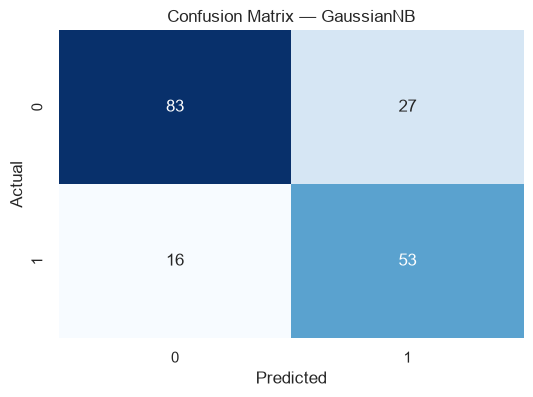

Classification report:
              precision    recall  f1-score   support

           0       0.84      0.75      0.79       110
           1       0.66      0.77      0.71        69

    accuracy                           0.76       179
   macro avg       0.75      0.76      0.75       179
weighted avg       0.77      0.76      0.76       179



In [25]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# TODO: print accuracy_score for both y_pred_scratch and y_pred_sklearn
accuracy_scratch = accuracy_score(y_test.values, y_pred_scratch)
accuracy_sklearn = accuracy_score(y_test.values, y_pred_sklearn)    

print(f"Accuracy (Scratch): {accuracy_scratch:.2f}")
print(f"Accuracy (Sklearn): {accuracy_sklearn:.2f}")

# TODO: compute confusion_matrix for y_pred_sklearn and plot it with sns.heatmap(annot=True)
cm = confusion_matrix(y_test.values, y_pred_sklearn)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — GaussianNB")
plt.show()

# TODO: print classification_report for y_pred_sklearn
print("Classification report:")
print(classification_report(y_test, y_pred_sklearn))

**3.6 Final Comparison: Does All That Preprocessing Actually Help?**

Train one more `GaussianNB` on a **minimally processed** baseline (just impute missing `age`, drop other categorical columns) and compare its cross-validated accuracy to Member B's fully processed pipeline from Section 3.4.

In [26]:
# TODO: build a quick baseline: X_baseline = titanic[['pclass','age','sibsp','parch','fare']] (imputed age only, no encoding/scaling/binning)
X_baseline = titanic[['pclass', 'age', 'sibsp', 'parch', 'fare']].copy()
y_baseline = titanic['survived'].copy()

# TODO: run the same cross_val_score(GaussianNB(), X_baseline, y, cv=5) on it
baseline_imputer = SimpleImputer(strategy='median')
X_baseline['age'] = baseline_imputer.fit_transform(X_baseline[['age']])

baseline_scores = cross_val_score(GaussianNB(), X_baseline, y_baseline, cv=5)


# TODO: print both mean CV accuracies side-by-side and comment on the difference
print("Mean CV accuracy (Baseline):", baseline_scores.mean())
print("Mean CV accuracy (Full Model):", scores.mean())


Mean CV accuracy (Baseline): 0.6768438892724876
Mean CV accuracy (Full Model): 0.7669063331035162


**Compare your 3 results:** from-scratch NB, `sklearn` NB on the full pipeline, and `sklearn` NB on the raw baseline. They should mostly agree in *direction* even if the exact numbers differ slightly.

#### **Wrap-Up: Group Reflection (Answer Together)**

As a group, discuss and write your answers in the cell below:

1. Which single preprocessing step from Part 2 do you think improved accuracy the most, and why?
2. How closely did your hand-computed Bayes' Theorem probability (Section 1.7) match the true empirical survival rate for women? If they didn't match exactly, why not?
3. Which Naive Bayes variant (`Gaussian`/`Multinomial`/`Bernoulli`/`Categorical`) would you choose for a spam-detection problem based on word counts, and why?
4. Why did we split the data into train/test **before** imputing, encoding, and scaling in Part 2, instead of doing it on the whole dataset first?

*Group answers here:*
1. I think one-hot encoding improved the accuracy the most because it converts categorical features such as sex and embarked into numerical features that Gaussian Naive Bayes can use properly. Without encoding, these categorical values cannot be directly handled as numerical inputs. However, the we does not test each preprocessing step individually, so this is an informed assumption rather than a measured comparison.

2. The hand-computed Bayes' Theorem probability matched the true empirical survival rate for women exactly (up to rounding). The Bayes calculation gave P(Survived | Female) = 0.742038, and the empirical value was also 0.742038. They match because both calculations are based on the same underlying dataset and Bayes' Theorem correctly relates the prior and conditional probabilities.

3. For spam detection based on word counts, we would choose Multinomial Naive Bayes. MultinomialNB is designed for discrete count features such as the number of times words appear in a document. This makes it suitable for representing word-frequency information in spam and non-spam emails.

4. Because Preprocessing steps such as calculating imputation values, encoding information, or scaling parameters should be learned only from the training data. If we preprocess the entire dataset first, information from the test set can influence the transformations, making the test accuracy overly optimistic. By fitting preprocessing only on the training set and then applying it to the test set, the test set remains an unseen evaluation set.